COU 07506 – Digital Signal Processing (DSP)
Week 03: Lab 1B — Convolution, Correlation and Difference Equations
Name: SALIMIN BURUHANI SHECHONGE
Registration No.: 240242411437
Class: BEng24coe-2
Group: 1
Date: 23/11/2026

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 3.1 — Convolution from the definition

In [3]:
def conv(x, h):
    N = len(x) + len(h) - 1          # output length L + M - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):  # only use valid h indices
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))          # expect [1 3 6 6 4 1]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))

# Pre-lab (a) check
print(conv([1, -1, 2], [2, 1, 0, 1]))
print(np.convolve([1, -1, 2], [2, 1, 0, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]
[ 2. -1.  3.  3. -1.  2.]
[ 2 -1  3  3 -1  2]


In [4]:
import time
rng = np.random.default_rng(0)
a = rng.standard_normal(2000)
b = rng.standard_normal(2000)

t0 = time.perf_counter(); y1 = conv(a, b);       t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y2 = np.convolve(a, b); t_np   = time.perf_counter() - t0

print(f"my conv      : {t_loop:.4f} s")
print(f"np.convolve  : {t_np:.6f} s")
print(f"speed-up     : {t_loop/t_np:.0f}x")
print("results agree:", np.allclose(y1, y2))

my conv      : 3.4378 s
np.convolve  : 0.002429 s
speed-up     : 1415x
results agree: True


## Task 3.2 — Smoothing a noisy signal by convolution

M =  3: RMS error vs clean sine = 0.301
M =  9: RMS error vs clean sine = 0.183
M = 25: RMS error vs clean sine = 0.267
no filter: RMS error vs clean sine = 0.509


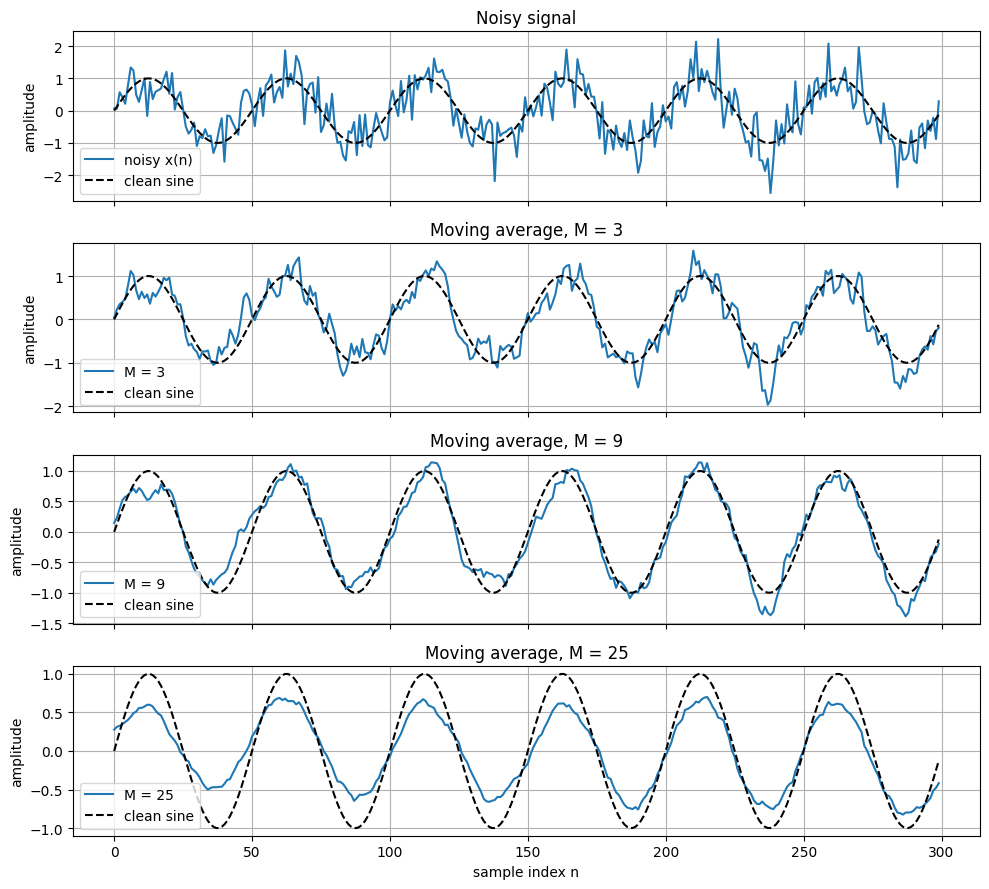

In [5]:
rng = np.random.default_rng(0)
n = np.arange(300)                                   # 0 <= n < 300
clean = np.sin(2*np.pi*n/50)                         # period = 50 samples
x = clean + 0.5*rng.standard_normal(len(n))          # add Gaussian noise

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
axes[0].plot(n, x, label="noisy x(n)")
axes[0].plot(n, clean, "k--", label="clean sine")
axes[0].set_title("Noisy signal"); axes[0].legend()

for ax, M in zip(axes[1:], [3, 9, 25]):
    h = np.ones(M) / M                               # moving-average filter
    y = np.convolve(x, h, mode="same")
    ax.plot(n, y, label=f"M = {M}")
    ax.plot(n, clean, "k--", label="clean sine")
    ax.set_title(f"Moving average, M = {M}"); ax.legend()
    err = np.sqrt(np.mean((y - clean)**2))
    print(f"M = {M:2d}: RMS error vs clean sine = {err:.3f}")

err0 = np.sqrt(np.mean((x - clean)**2))
print(f"no filter: RMS error vs clean sine = {err0:.3f}")

for ax in axes:
    ax.set_ylabel("amplitude"); ax.grid(True)
axes[-1].set_xlabel("sample index n")
plt.tight_layout(); plt.show()

## Task 3.3 — Testing linearity and time-invariance

In [6]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}

for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]      # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]   # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


## Task 3.4 — Finding a hidden delay with cross-correlation

estimated delay: 37 samples


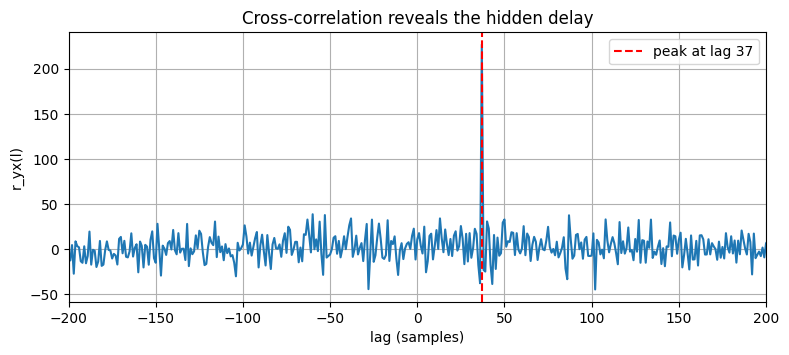

In [7]:
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)                       # transmitted signal
true_delay = 37
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + 0.5*rng.standard_normal(500)

r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")
est = lags[np.argmax(r)]
print("estimated delay:", est, "samples")

plt.plot(lags, r)
plt.axvline(est, color="r", ls="--", label=f"peak at lag {est}")
plt.xlim(-200, 200)
plt.xlabel("lag (samples)"); plt.ylabel("r_yx(l)")
plt.title("Cross-correlation reveals the hidden delay")
plt.grid(True); plt.legend(); plt.show()

In [8]:
for sigma in [0.5, 1, 2, 4]:
    rng = np.random.default_rng(1)
    x = rng.standard_normal(500)
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + sigma*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    print(f"noise std = {sigma}: estimated delay = {lags[np.argmax(r)]} samples")

noise std = 0.5: estimated delay = 37 samples
noise std = 1: estimated delay = 37 samples
noise std = 2: estimated delay = 37 samples
noise std = 4: estimated delay = 87 samples


In [9]:
print("distance =", 343 * est / fs, "m")

distance = 12.691 m


## Task 3.5 — Difference equation

 n |   loop   | lfilter  | closed form
 0 |  1.00000 |  1.00000 |  1.00000
 1 |  1.75000 |  1.75000 |  1.75000
 2 |  1.18750 |  1.18750 |  1.18750
 3 |  0.67188 |  0.67188 |  0.67188
 4 |  0.35547 |  0.35547 |  0.35547
 5 |  0.18262 |  0.18262 |  0.18262
 6 |  0.09253 |  0.09253 |  0.09253
 7 |  0.04657 |  0.04657 |  0.04657
 8 |  0.02336 |  0.02336 |  0.02336
 9 |  0.01170 |  0.01170 |  0.01170
loop = lfilter: True
loop = closed form: True


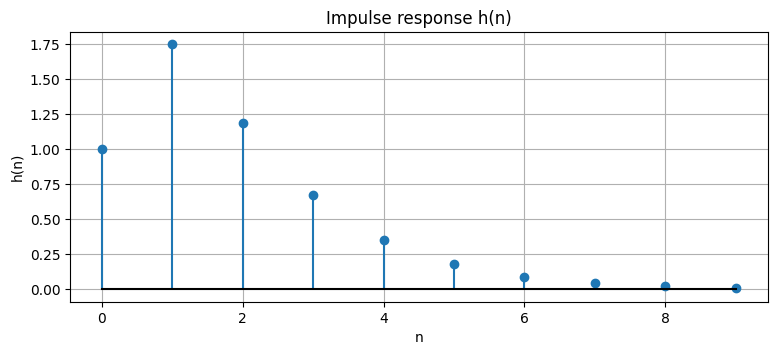

In [10]:
N = 10
n = np.arange(N)
impulse = np.zeros(N); impulse[0] = 1

# 1. Direct recursion with a for loop
h_loop = np.zeros(N)
for i in range(N):
    xn  = impulse[i]
    xn1 = impulse[i-1] if i >= 1 else 0.0
    y1  = h_loop[i-1]  if i >= 1 else 0.0
    y2  = h_loop[i-2]  if i >= 2 else 0.0
    h_loop[i] = xn + xn1 + 0.75*y1 - 0.125*y2

# 2. With lfilter
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)

# 3. Closed form from handout Example 2.5
h_cf = 6*(0.5)**n - 5*(0.25)**n

print(" n |   loop   | lfilter  | closed form")
for i in range(N):
    print(f"{i:2d} | {h_loop[i]:8.5f} | {h_lf[i]:8.5f} | {h_cf[i]:8.5f}")
print("loop = lfilter:", np.allclose(h_loop, h_lf))
print("loop = closed form:", np.allclose(h_loop, h_cf))

plt.stem(n, h_loop, basefmt="k-")
plt.xlabel("n"); plt.ylabel("h(n)"); plt.title("Impulse response h(n)")
plt.grid(True); plt.show()

step response final value: 5.333333333333333
H(1) = sum(b)/sum(a)    : 5.333333333333333


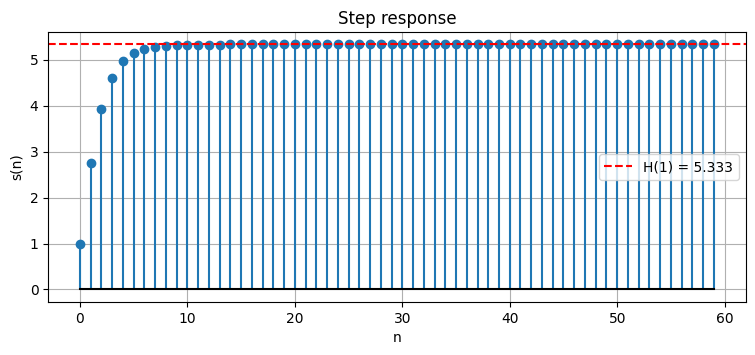

In [11]:
step = np.ones(60)
s = signal.lfilter([1, 1], [1, -0.75, 0.125], step)

print("step response final value:", s[-1])
print("H(1) = sum(b)/sum(a)    :", sum([1, 1]) / sum([1, -0.75, 0.125]))

plt.stem(np.arange(60), s, basefmt="k-")
plt.axhline(16/3, color="r", ls="--", label="H(1) = 5.333")
plt.xlabel("n"); plt.ylabel("s(n)"); plt.title("Step response")
plt.grid(True); plt.legend(); plt.show()